# Calcolo variazione tra due oggetti semanticamente vicini

In [8]:
import sys
sys.path.append("/Experiments/riccardop02")

import torch
import numpy as np
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"
import matplotlib.pyplot as plt

# --- 1. SETUP ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# L'equivalente "base" finetunato da FiT3D si chiama dinov2_base_fine
MODEL_NAME = "dinov2_base_fine"

cache_dir = "/Experiments/riccardop02/torch_cache" 
torch.hub.set_dir(cache_dir)
print(f"Cartella di download impostata su: {cache_dir}")

# FiT3D va caricato via torch.hub dal repository GitHub dell'autore
print(f"Caricamento {MODEL_NAME} dal repository FiT3D...")
model = torch.hub.load("ywyue/FiT3D", MODEL_NAME, trust_repo=True).to(device).eval()

# Spegniamo i gradienti per fare solo inferenza
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"FiT3D caricato — {n_params/1e6:.1f}M parametri")

# --- 2. IMAGE PROCESSING ---
# Invece di AutoImageProcessor, usiamo torchvision.
# Ridimensioniamo a 224x224 (multiplo di 14) per generare una griglia perfetta 16x16.
transform = T.Compose([
    T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

# --- 3. ESTRAZIONE FEATURES ---
@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2, norm_mode="global", normalize=True):
    # Processa l'immagine (img deve essere un oggetto PIL Image)
    x = transform(img).unsqueeze(0).to(device)  # shape: (1, 3, 224, 224)
    
    # --- Estrazione manuale dei layer intermedi ---
    feat = model.patch_embed(x)
    feat = model._pos_embed(feat)
    feat = model.norm_pre(feat)
    
    hs = []
    for blk in model.blocks:
        feat = blk(feat)
        hs.append(feat)
    
    parts = []
    for L in layers:
        
        h = hs[L] 
        
       
        if (L == -1 or L == len(hs) - 1) and hasattr(model, 'norm') and model.norm is not None:
            h = model.norm(h)
                
        h = h[0] 
        
        cls_tensor = h[0]  
        P = h[1:]          
        
        # Calcoliamo il lato della griglia (es. 256 patch -> 16x16)
        side = int(P.shape[0] ** 0.5) 
        
        if token == "cls":
            v = cls_tensor
            
        elif token == "ptc":
            v = P.flatten()
            
        elif token == "pool":
            g = P.reshape(side, side, -1)         
            step = side // grid                   
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  

        elif token == "hybrid":
            cls_norm = F.normalize(cls_tensor, dim=-1)           
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool_norm = F.normalize(torch.cat(cells), dim=-1)         
            v = torch.cat([cls_norm, pool_norm])                           

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
        
    return torch.cat(parts, dim=-1)

print("Extract Features Ready!")

device: cuda
Cartella di download impostata su: /Experiments/riccardop02/torch_cache
Caricamento dinov2_base_fine dal repository FiT3D...


Using cache found in /Experiments/riccardop02/torch_cache/ywyue_FiT3D_main


FiT3D caricato — 86.6M parametri
Extract Features Ready!


In [9]:
@torch.no_grad()
def compare(img1, img2, layers=[-1], token="pool"):
    e1 = extract_features2(img1, layers=layers, token=token)
    e2 = extract_features2(img2, layers=layers, token=token)

    cos_sim  = F.cosine_similarity(e1, e2, dim=0).item()
    cos_dist = 1.0 - cos_sim
    l2       = torch.norm(e1 - e2).item()
    l1       = torch.abs(e1 - e2).sum().item()      # la distanza "di JEPA"
    return {"cos_sim": cos_sim, "cos_dist": cos_dist, "l2": l2, "l1": l1}

# --- prova: posa vicina vs posa lontana ---
img0     = Image.open(RENDERS / "ycbv" / "obj_000017_pose0036_rx+180_ry+000_rz+180_tx+000_ty+000_tz-655.png").convert("RGB")
img_near = Image.open(RENDERS / "ycbv" / "obj_000017_pose0017_rx+000_ry+085_rz+000_tx+000_ty+000_tz-655.png").convert("RGB")
img_nearer = Image.open(RENDERS / "ycbv" / "obj_000017_pose0026_rx+180_ry+050_rz+180_tx+000_ty+000_tz-655.png").convert("RGB")
img_far  = Image.open(RENDERS / "ycbv" / "obj_000002_pose0047_rx+180_ry-055_rz+180_tx+000_ty+000_tz-652.png").convert("RGB")

dn = compare(img0, img_near)
df = compare(img0, img_far)
dnn = compare(img0, img_nearer)
print(f"vicina  -> cos_dist {dn['cos_dist']:.4f} | L2 {dn['l2']:.4f} | L1 {dn['l1']:.4f}")
print(f"vicinissima  -> cos_dist {dnn['cos_dist']:.4f} | L2 {dnn['l2']:.4f} | L1 {dnn['l1']:.4f}")
print(f"lontana -> cos_dist {df['cos_dist']:.4f} | L2 {df['l2']:.4f} | L1 {df['l1']:.4f}")

vicina  -> cos_dist 0.1772 | L2 0.5954 | L1 25.7415
vicinissima  -> cos_dist 0.0197 | L2 0.1987 | L1 8.8258
lontana -> cos_dist 0.2116 | L2 0.6505 | L1 28.2364


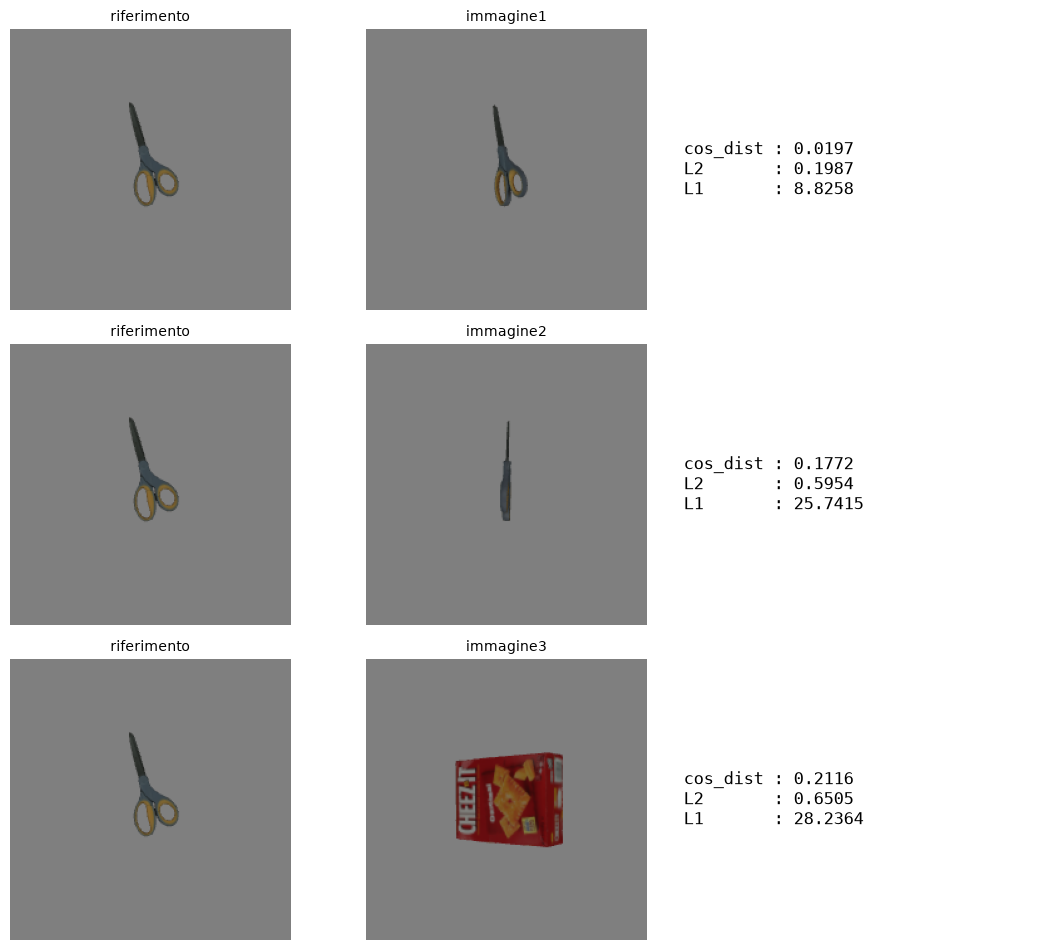

In [10]:
def plot_comparisons(ref_img, others, labels, layers=[-1], token="pool"):
    """
    Per ogni confronto mostra: [ref | altra | metriche].
      ref_img : immagine di riferimento (PIL)
      others  : lista di immagini PIL da confrontare con ref
      labels  : lista di etichette (es. ["vicinissima", "vicina", "lontana"])
    """
    n = len(others)
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.2 * n))
    if n == 1:
        axes = axes[None, :]          # uniforma la forma quando c'è un solo confronto

    for row, (img, lab) in enumerate(zip(others, labels)):
        d = compare(ref_img, img, layers=layers, token=token)

        axes[row, 0].imshow(ref_img)
        axes[row, 0].set_title("riferimento", fontsize=10)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img)
        axes[row, 1].set_title(lab, fontsize=10)
        axes[row, 1].axis("off")

        txt = (f"cos_dist : {d['cos_dist']:.4f}\n"
               f"L2       : {d['l2']:.4f}\n"
               f"L1       : {d['l1']:.4f}")
        axes[row, 2].text(0.0, 0.5, txt, fontsize=12, family="monospace",
                          va="center", ha="left")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()


# --- uso: ordina dal più vicino al più lontano ---
plot_comparisons(
    ref_img = img0,
    others  = [img_nearer, img_near, img_far],
    labels  = ["immagine1", "immagine2", "immagine3"],
)

In [11]:
def plot_distance_scale(ref_img, others, kinds, labels=None,
                        token="pool", metric="l1", n_show=12):
    """
    ref_img : immagine di riferimento (PIL)
    others  : lista di immagini PIL
    kinds   : per ogni immagine: "same" (stesso ogg, posa div) o "diff" (ogg div)
    metric  : "l1" | "l2" | "cos_dist"
    """
    dists = np.array([compare(ref_img, im, token=token)[metric] for im in others])
    kinds = np.array(kinds)

    order = np.argsort(dists)
    dists, kinds = dists[order], kinds[order]
    others = [others[i] for i in order]

    colors = ["#2c7fb8" if k == "same" else "#d95f0e" for k in kinds]

    sel = np.linspace(0, len(others)-1, min(n_show, len(others))).astype(int)
    fig = plt.figure(figsize=(max(10, len(sel)*1.1), 7))
    gs = fig.add_gridspec(2, len(sel), height_ratios=[2.2, 1.3])

    axb = fig.add_subplot(gs[0, :])
    axb.bar(range(len(dists)), dists, color=colors, width=0.9)
    axb.set_ylabel(metric.upper())
    axb.set_xlabel("immagini ordinate per distanza dal riferimento")
    axb.set_title("Scala di differenza dal riferimento — blu = stesso oggetto, arancio = oggetto diverso")
    same_max = dists[kinds=="same"].max() if (kinds=="same").any() else 0
    axb.axhline(same_max, ls="--", c="#2c7fb8", lw=1,
                label=f"max {metric.upper()} stesso oggetto = {same_max:.2f}")
    axb.legend(fontsize=9)

    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[1, k])
        ax.imshow(others[idx])
        ax.set_title(f"{dists[idx]:.1f}", fontsize=8)
        for s in ax.spines.values():
            s.set_color(colors[idx]); s.set_linewidth(3)
        ax.set_xticks([]); ax.set_yticks([])

    plt.tight_layout()
    plt.show()

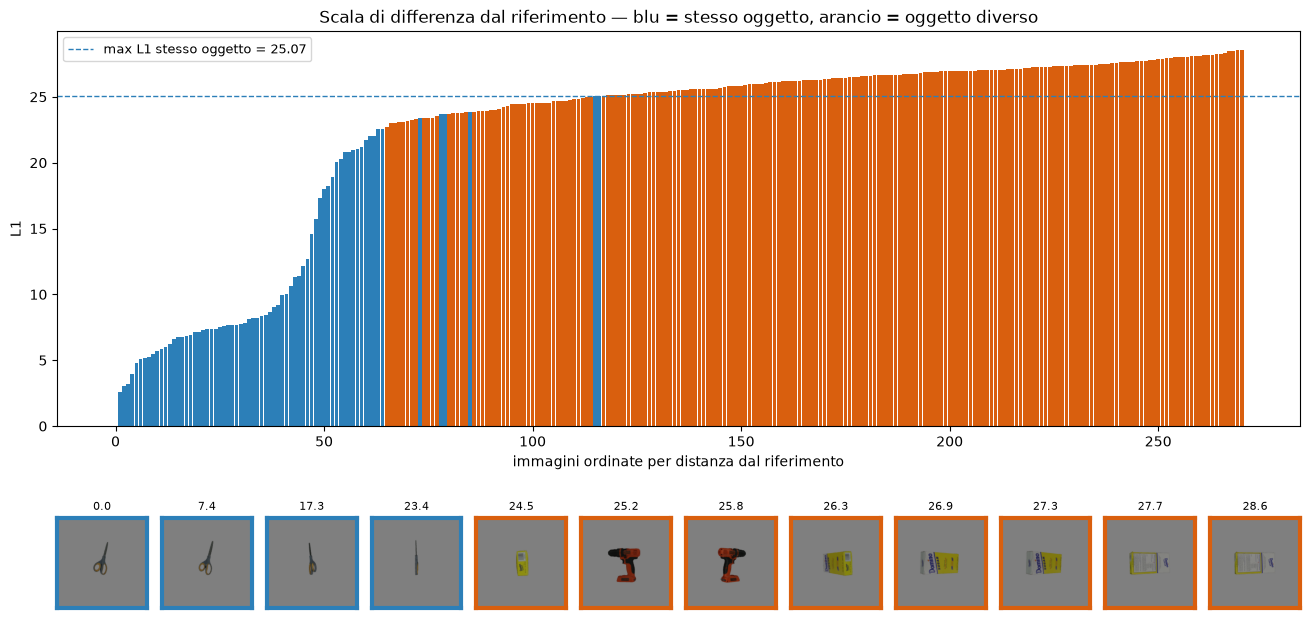

In [12]:
import pandas as pd

DATASET = "ycbv"
REF_OBJ = "obj_000017"          # l'oggetto di riferimento (le forbici)
DIFF_OBJS = ["obj_000002", "obj_000003", "obj_000015"]   # oggetti diversi
N_SAME, N_DIFF = 200, 200

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")

# riferimento = prima posa dell'oggetto di riferimento
ref_row = df[df.object==REF_OBJ].iloc[5]
ref_img = Image.open(RENDERS / ref_row["image"]).convert("RGB")

others, kinds = [], []
# pose DIVERSE dello STESSO oggetto
same_rows = df[df.object==REF_OBJ].iloc[1:N_SAME+1]
for _, r in same_rows.iterrows():
    others.append(Image.open(RENDERS / r["image"]).convert("RGB")); kinds.append("same")
# pose di oggetti DIVERSI
diff_rows = df[df.object.isin(DIFF_OBJS)].sample(N_DIFF, random_state=0)
for _, r in diff_rows.iterrows():
    others.append(Image.open(RENDERS / r["image"]).convert("RGB")); kinds.append("diff")

plot_distance_scale(ref_img, others, kinds, token="pool", metric="l1", n_show=12)

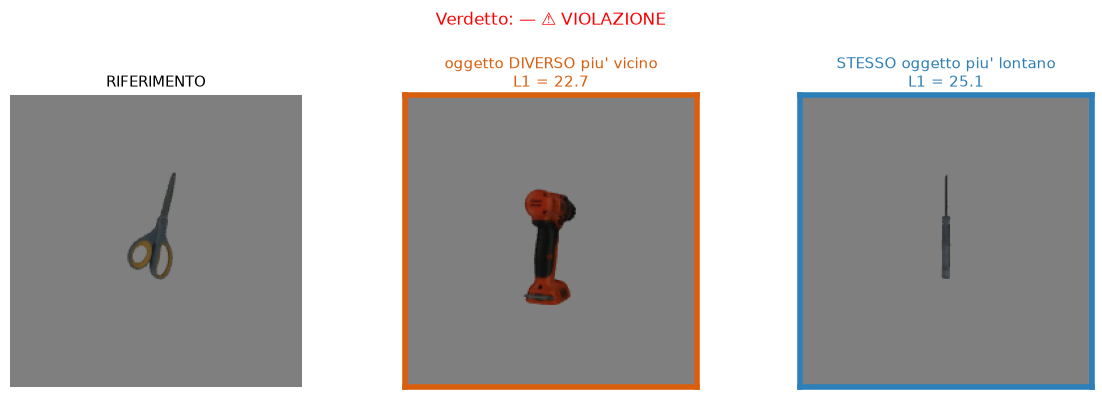

{'diff_min': np.float64(22.671016693115234),
 'same_max': np.float64(25.074329376220703),
 'violazione': np.True_}

In [13]:
def show_worst_case(ref_img, others, kinds, token="pool", metric="l1"):
    """
    Mostra il caso peggiore per E2:
      - l'oggetto DIVERSO piu' VICINO al riferimento (dovrebbe essere lontano)
      - la posa STESSO oggetto piu' LONTANA dal riferimento (dovrebbe essere vicina)
    Se diff_min < same_max -> VIOLAZIONE: un altro oggetto e' piu' simile di una posa propria.
    """
    dists = np.array([compare(ref_img, im, token=token)[metric] for im in others])
    kinds = np.array(kinds)

    same_idx = np.where(kinds == "same")[0]
    diff_idx = np.where(kinds == "diff")[0]

    # peggiori: diff piu' vicino, same piu' lontano
    worst_diff = diff_idx[np.argmin(dists[diff_idx])]   # oggetto diverso piu' simile
    worst_same = same_idx[np.argmax(dists[same_idx])]   # posa propria piu' diversa

    d_diff, d_same = dists[worst_diff], dists[worst_same]
    violazione = d_diff < d_same

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(ref_img); axes[0].set_title("RIFERIMENTO", fontsize=11); axes[0].axis("off")

    axes[1].imshow(others[worst_diff])
    axes[1].set_title(f"oggetto DIVERSO piu' vicino\n{metric.upper()} = {d_diff:.1f}",
                      fontsize=11, color="#d95f0e")
    for s in axes[1].spines.values(): s.set_color("#d95f0e"); s.set_linewidth(4)
    axes[1].set_xticks([]); axes[1].set_yticks([])

    axes[2].imshow(others[worst_same])
    axes[2].set_title(f"STESSO oggetto piu' lontano\n{metric.upper()} = {d_same:.1f}",
                      fontsize=11, color="#2c7fb8")
    for s in axes[2].spines.values(): s.set_color("#2c7fb8"); s.set_linewidth(4)
    axes[2].set_xticks([]); axes[2].set_yticks([])

    verdetto = ("⚠ VIOLAZIONE"
                if violazione else
                "OK")
    fig.suptitle(f"Verdetto: — {verdetto}\n",
                 fontsize=12, color="red" if violazione else "green")
    plt.tight_layout()
    plt.show()
    return {"diff_min": d_diff, "same_max": d_same, "violazione": violazione}


# usa lo stesso set della cella precedente (ref_img, others, kinds)
show_worst_case(ref_img, others, kinds, token="pool", metric="l1")

pose allineate (rotazione + traslazione): False
tz di A: -362.66  |  tz di B: -556.30
riallineati su 72 pose comuni — rotazioni allineate: True


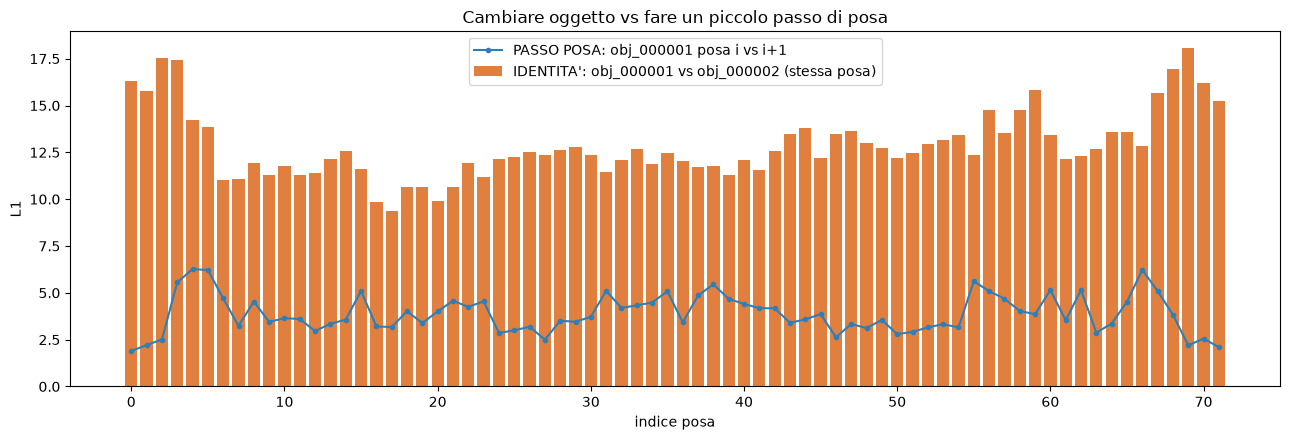

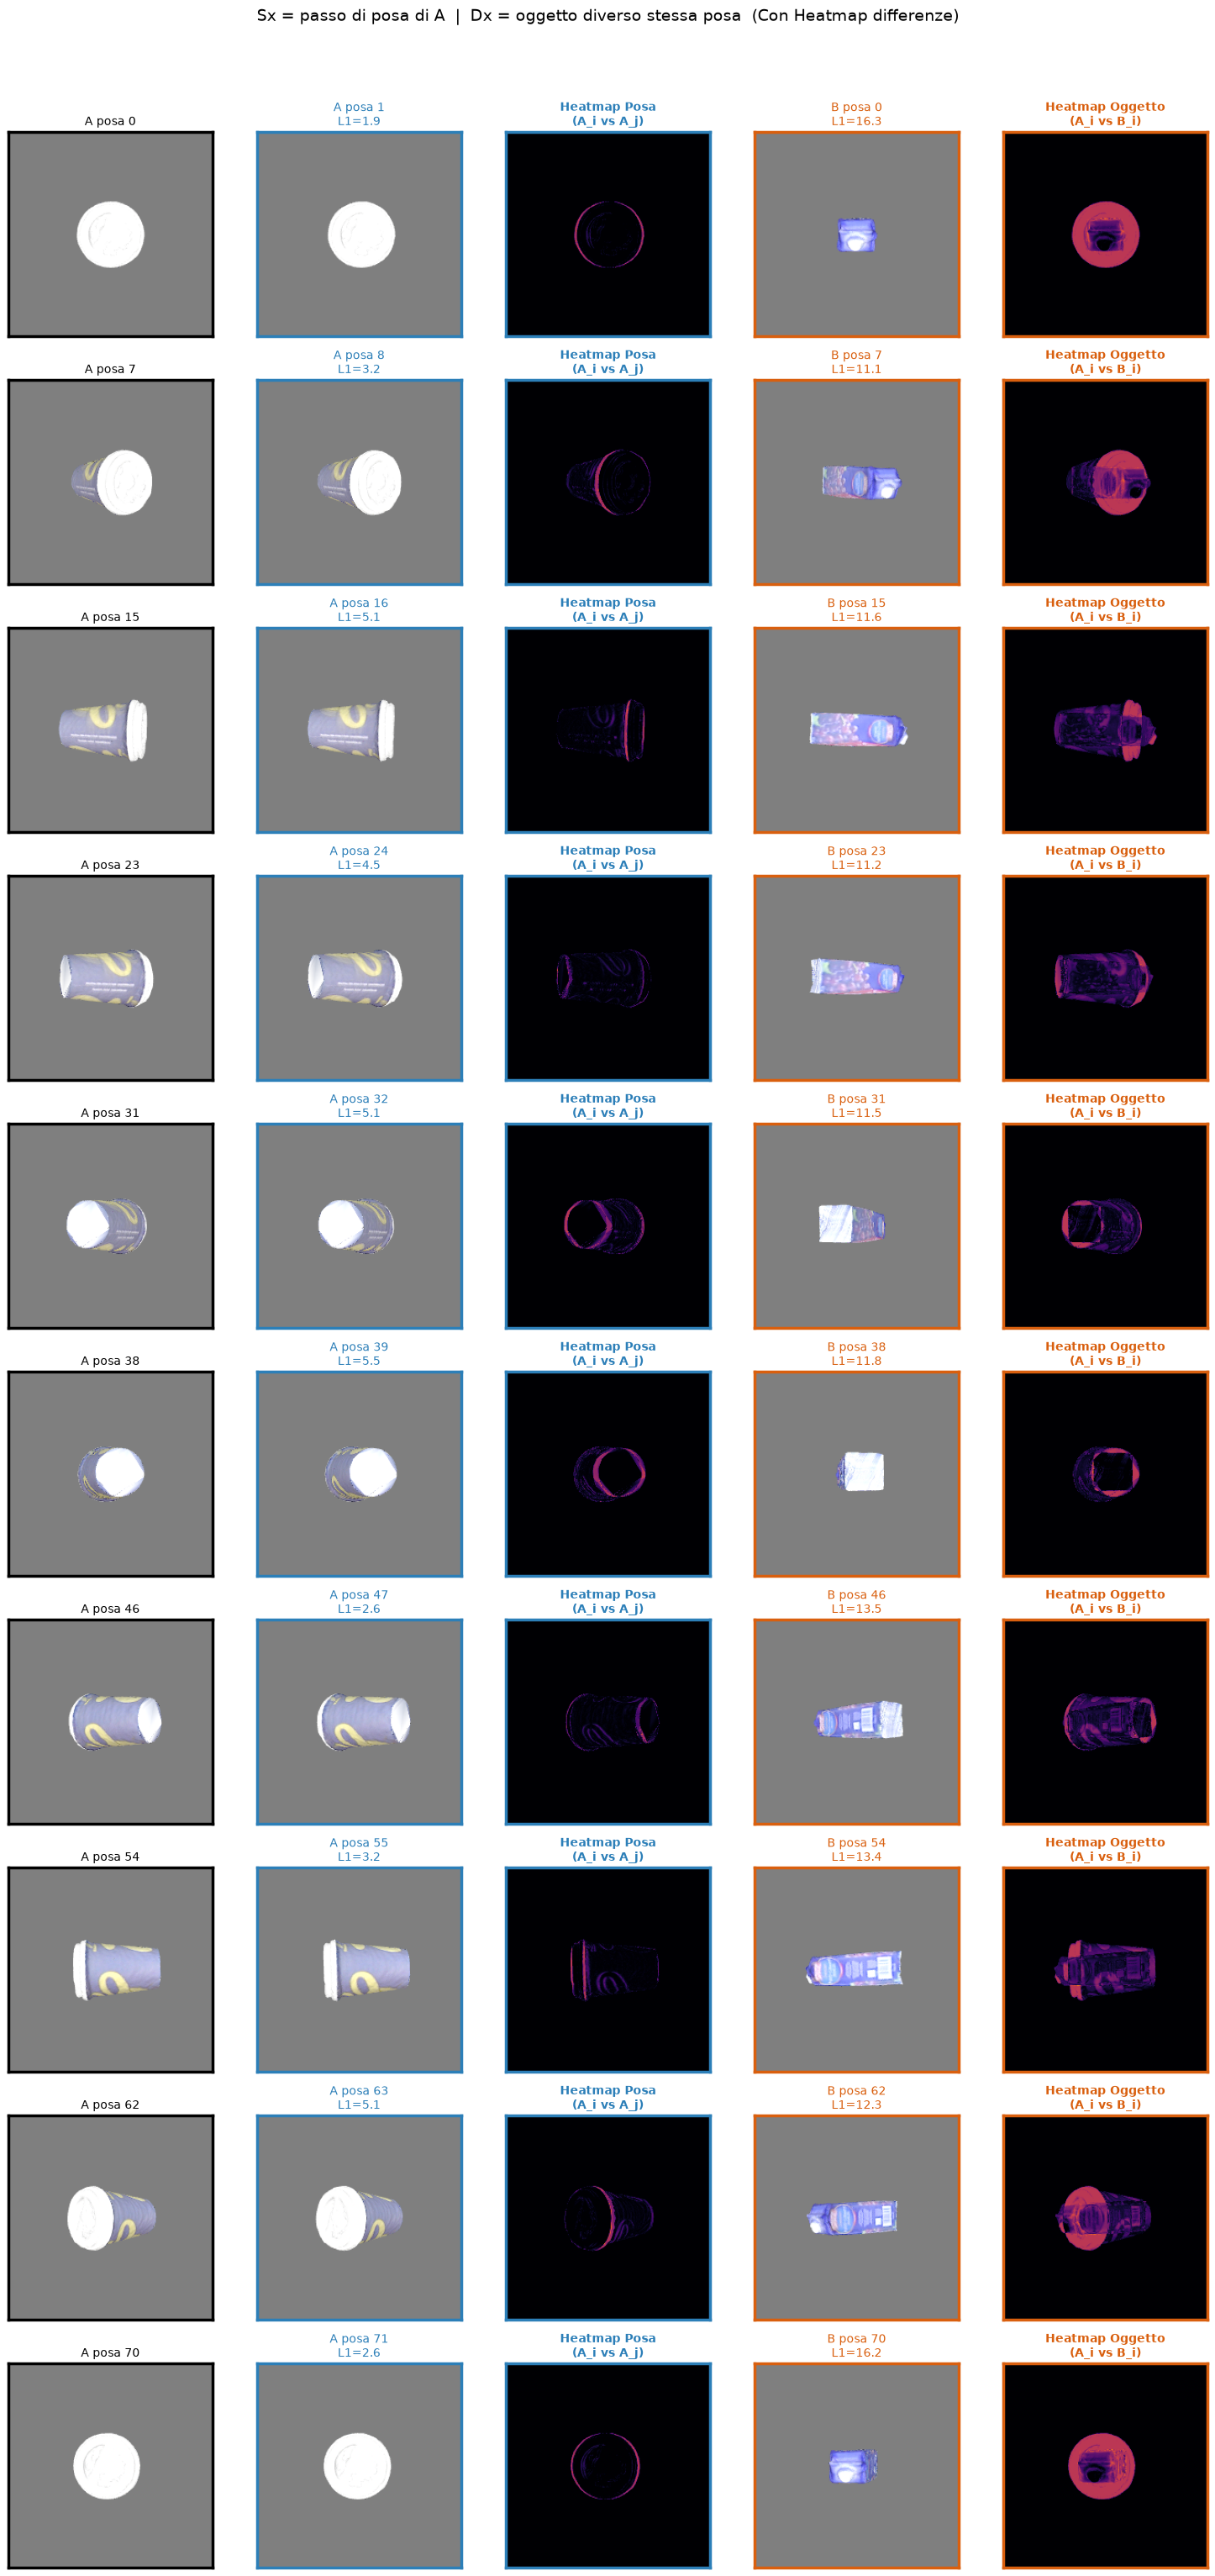

In [14]:
import pandas as pd

DATASET = "icbin_rotation"
OBJ_A, OBJ_B = "obj_000001", "obj_000002"
TOKEN = "pool"

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object==OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object==OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B)); A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")
if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

def emb(row):
    return extract_features2(Image.open(RENDERS / row["image"]).convert("RGB"), token=TOKEN)

# precalcola embedding di A e B
embA = [emb(A.iloc[i]) for i in range(n)]
embB = [emb(B.iloc[i]) for i in range(n)]

ident, step = [], []
for i in range(n):
    ident.append(torch.abs(embA[i] - embB[i]).sum().item())          # A vs B, stessa posa
    j = (i + 1) % n
    step.append(torch.abs(embA[i] - embA[j]).sum().item())           # A posa i vs A posa i+1
ident, step = np.array(ident), np.array(step)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA ---
# ==========================================
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(n)
ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
ax.set_xlabel("indice posa"); ax.set_ylabel("L1")
ax.set_title("Cambiare oggetto vs fare un piccolo passo di posa")
ax.legend()
plt.tight_layout(); plt.show()

# ==========================================
# --- GRAFICO 2: IMMAGINI E HEATMAP --------
# ==========================================
SEL = np.linspace(0, n-2, 10).astype(int)
fig, axes = plt.subplots(len(SEL), 5, figsize=(15, 3*len(SEL)))
for r, i in enumerate(SEL):
    j = (i + 1) % n
    imgA_i = np.array(Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    imgA_j = np.array(Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB"), dtype=np.float32)
    imgB_i = np.array(Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    diff_pose = np.abs(imgA_i - imgA_j).mean(axis=2)
    diff_obj  = np.abs(imgA_i - imgB_i).mean(axis=2)

    imgs = [imgA_i, imgA_j, diff_pose, imgB_i, diff_obj]
    titles = [f"A posa {i}", f"A posa {j}\nL1={step[i]:.1f}", "Heatmap Posa\n(A_i vs A_j)",
              f"B posa {i}\nL1={ident[i]:.1f}", "Heatmap Oggetto\n(A_i vs B_i)"]
    cols = ["black", "#2c7fb8", "#2c7fb8", "#d95f0e", "#d95f0e"]

    for c, (img, t, col) in enumerate(zip(imgs, titles, cols)):
        if "Heatmap" in t:
            axes[r, c].imshow(img, cmap="inferno", vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(t, fontsize=10, color=col,
                             fontweight='bold' if "Heatmap" in t else 'normal')
        for s in axes[r, c].spines.values():
            s.set_color(col); s.set_linewidth(2.5)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

plt.suptitle("Sx = passo di posa di A  |  Dx = oggetto diverso stessa posa  (Con Heatmap differenze)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

OGGETTI SEMANTICAMENTE VICINI

pose allineate (rotazione + traslazione): False
tz di A: -257.15  |  tz di B: -259.36
riallineati su 200 pose comuni — rotazioni allineate: True


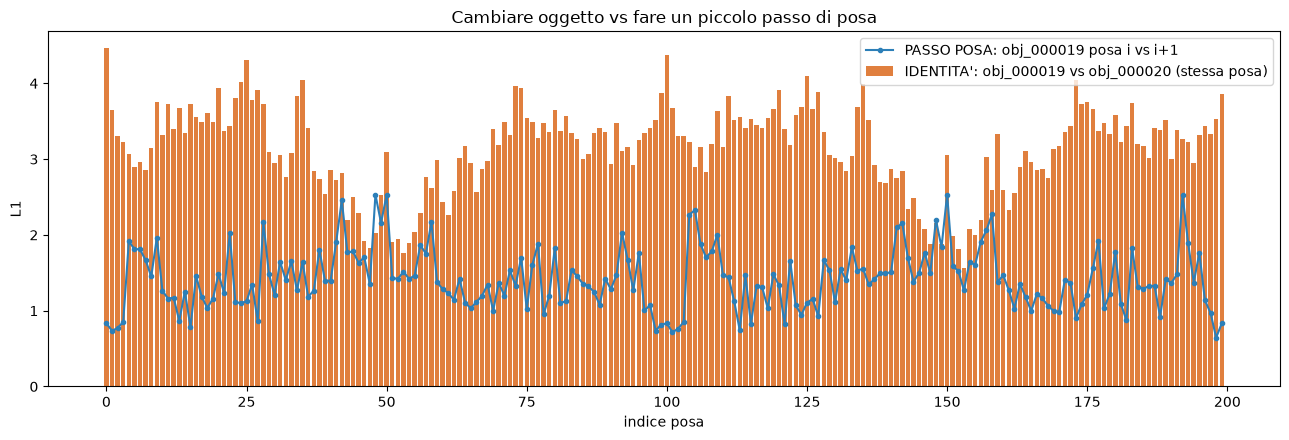

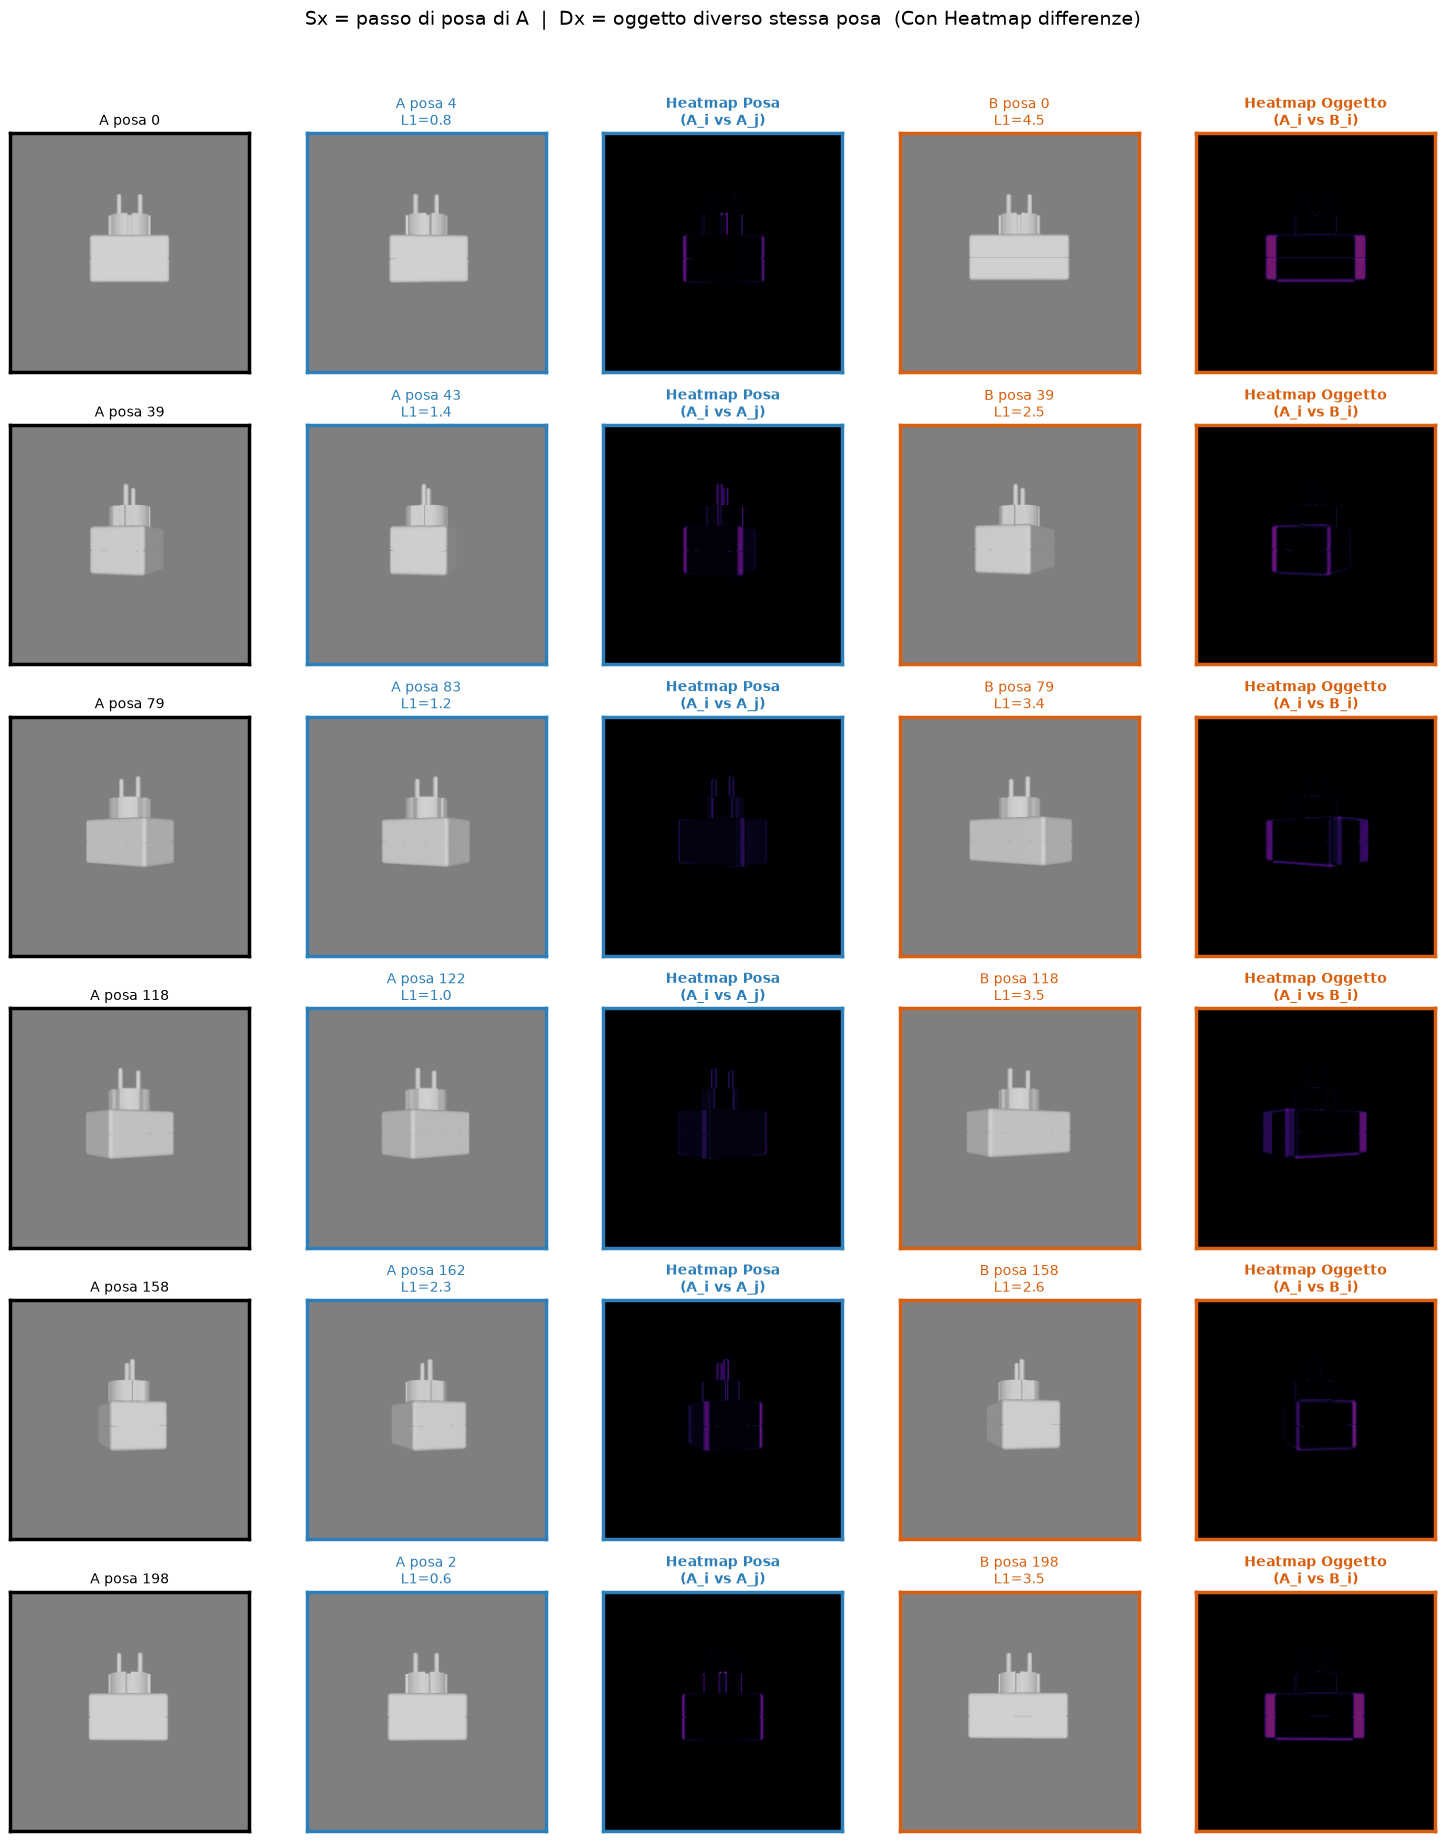

In [15]:


DATASET = "tless_translation"
OBJ_A, OBJ_B = "obj_000019", "obj_000020"
TOKEN = "pool"


df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object==OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object==OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B)); A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")
if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

def emb(row):
    return extract_features2(Image.open(RENDERS / row["image"]).convert("RGB"), token=TOKEN)

# precalcola embedding di A e B
embA = [emb(A.iloc[i]) for i in range(n)]
embB = [emb(B.iloc[i]) for i in range(n)]

ident, step = [], []
for i in range(n):
    ident.append(torch.abs(embA[i] - embB[i]).sum().item())          # A vs B, stessa posa
    j = (i + 1) % n
    step.append(torch.abs(embA[i] - embA[j]).sum().item())           # A posa i vs A posa i+1
ident, step = np.array(ident), np.array(step)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA ---
# ==========================================
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(n)
ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
ax.set_xlabel("indice posa"); ax.set_ylabel("L1")
ax.set_title("Cambiare oggetto vs fare un piccolo passo di posa")
ax.legend()
plt.tight_layout(); plt.show()

# ==========================================
# --- GRAFICO 2: IMMAGINI E HEATMAP --------
# ==========================================
SEL = np.linspace(0, n-2, 6).astype(int)
fig, axes = plt.subplots(len(SEL), 5, figsize=(15, 3*len(SEL)))
for r, i in enumerate(SEL):
    j = (i + 4) % n
    imgA_i = np.array(Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    imgA_j = np.array(Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB"), dtype=np.float32)
    imgB_i = np.array(Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    diff_pose = np.abs(imgA_i - imgA_j).mean(axis=2)
    diff_obj  = np.abs(imgA_i - imgB_i).mean(axis=2)

    imgs = [imgA_i, imgA_j, diff_pose, imgB_i, diff_obj]
    titles = [f"A posa {i}", f"A posa {j}\nL1={step[i]:.1f}", "Heatmap Posa\n(A_i vs A_j)",
              f"B posa {i}\nL1={ident[i]:.1f}", "Heatmap Oggetto\n(A_i vs B_i)"]
    cols = ["black", "#2c7fb8", "#2c7fb8", "#d95f0e", "#d95f0e"]

    for c, (img, t, col) in enumerate(zip(imgs, titles, cols)):
        if "Heatmap" in t:
            axes[r, c].imshow(img, cmap="inferno", vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(t, fontsize=10, color=col,
                             fontweight='bold' if "Heatmap" in t else 'normal')
        for s in axes[r, c].spines.values():
            s.set_color(col); s.set_linewidth(2.5)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

plt.suptitle("Sx = passo di posa di A  |  Dx = oggetto diverso stessa posa  (Con Heatmap differenze)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

pose allineate (rotazione + traslazione): False
tz di A: -279.00  |  tz di B: -274.93
riallineati su 200 pose comuni — rotazioni allineate: True


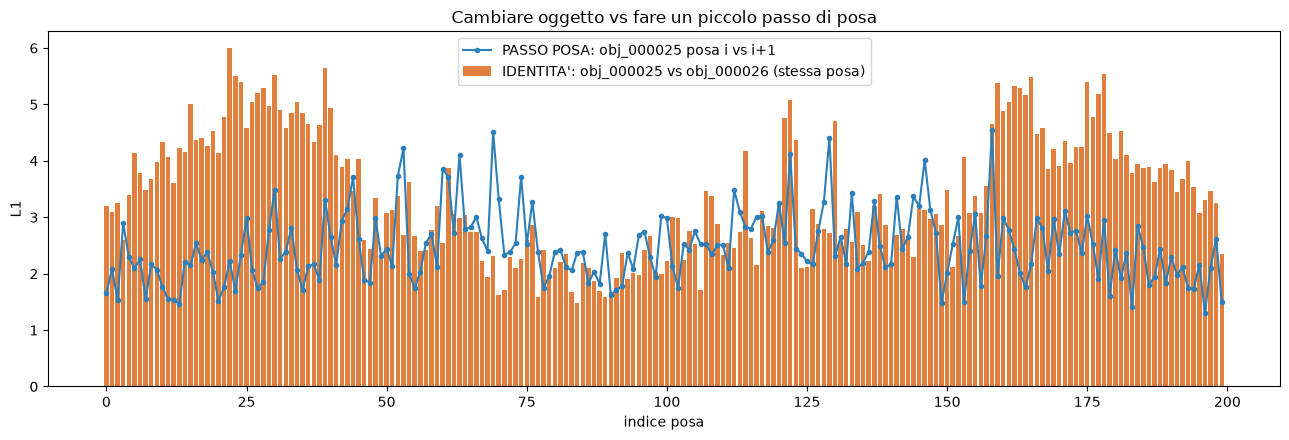

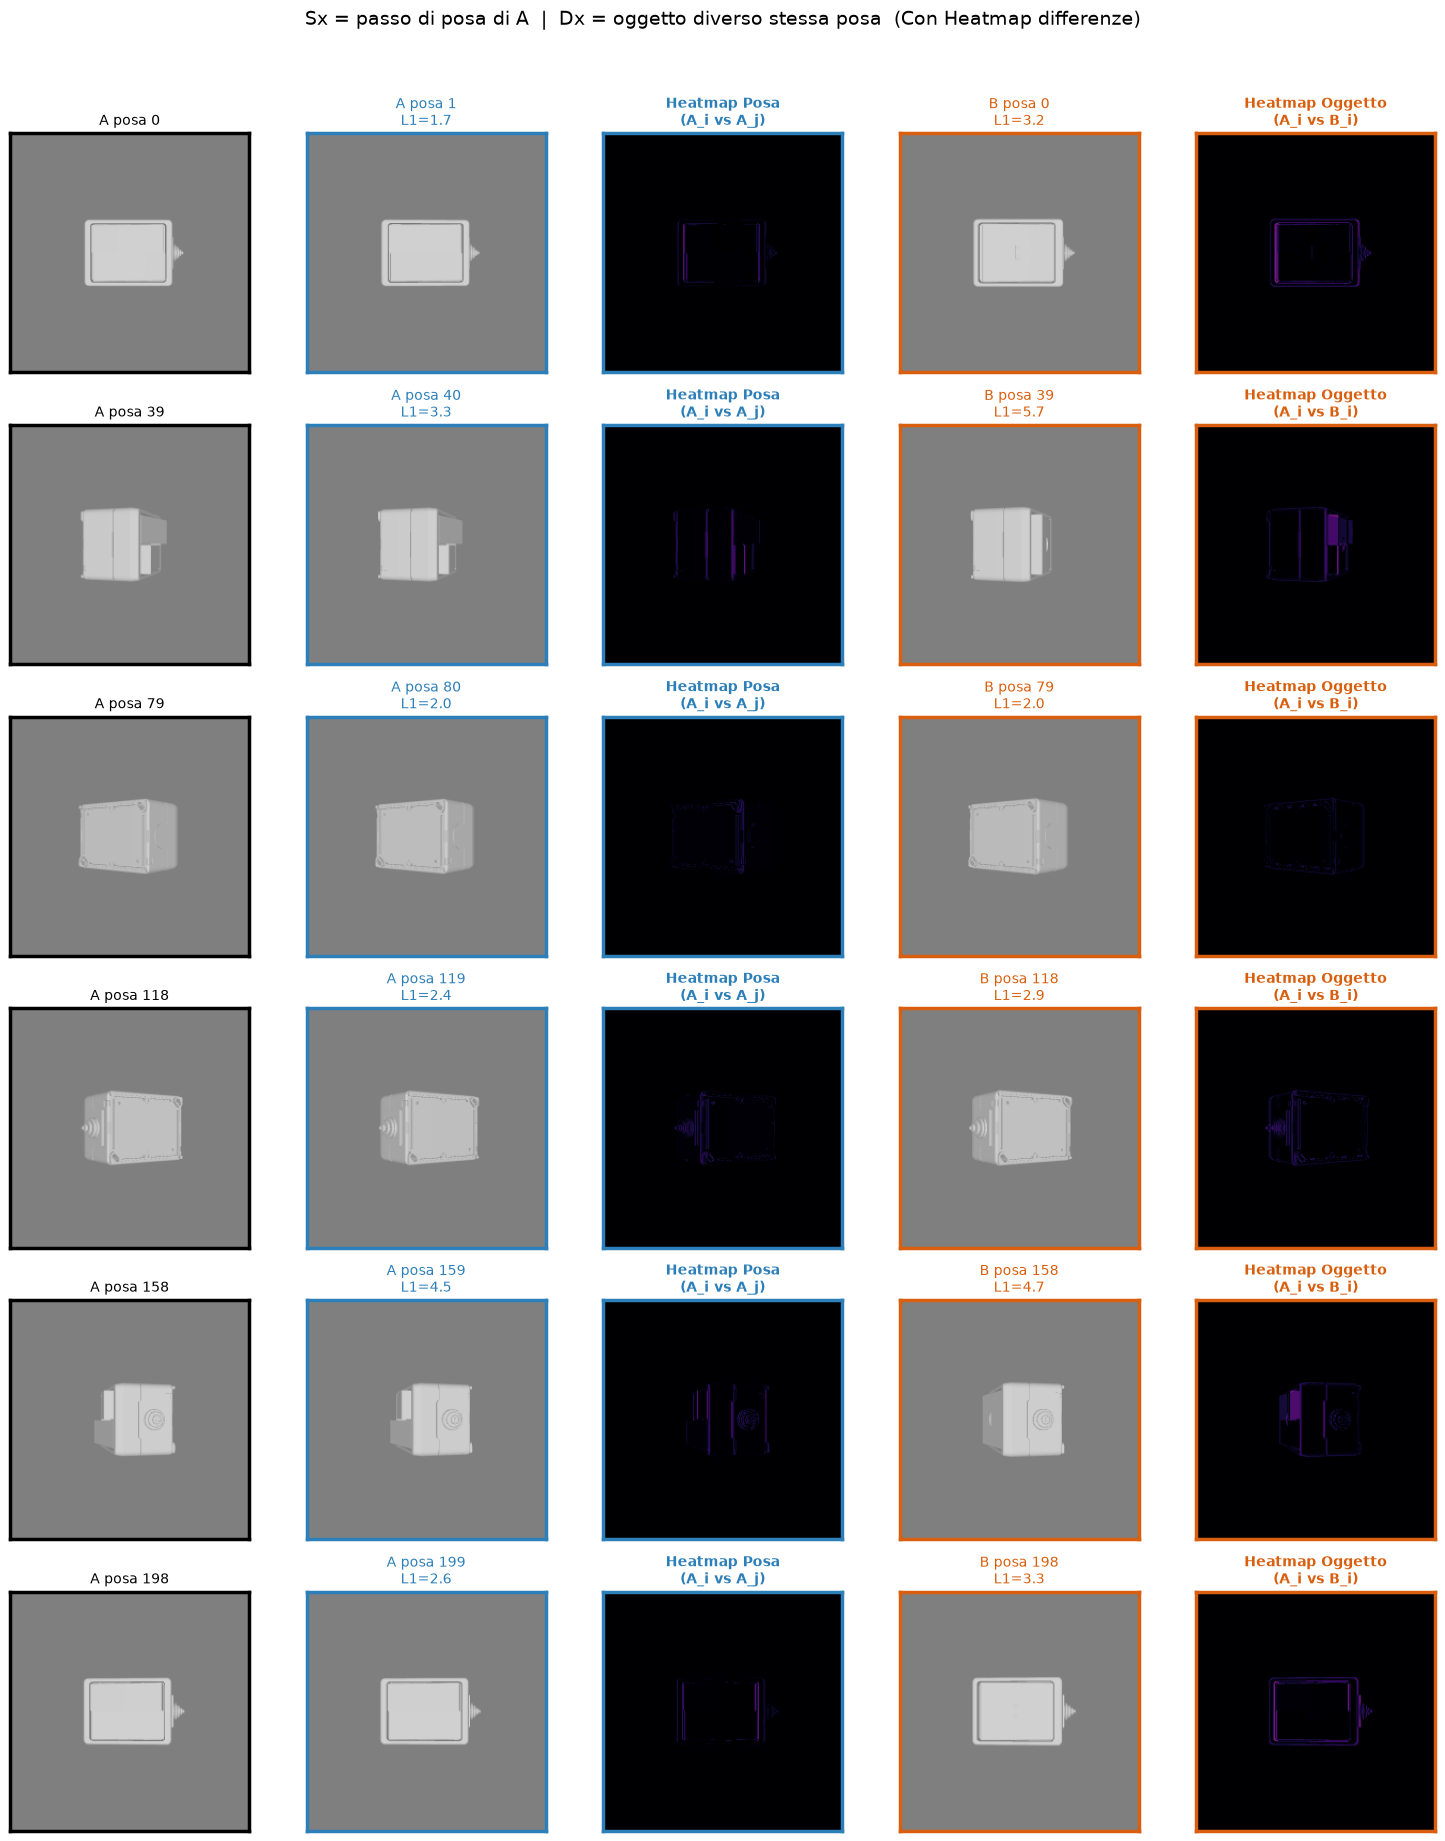

In [16]:

DATASET = "tless_translation"
OBJ_A, OBJ_B = "obj_000025", "obj_000026"
TOKEN = "pool"


df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object==OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object==OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B)); A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")
if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

def emb(row):
    return extract_features2(Image.open(RENDERS / row["image"]).convert("RGB"), token=TOKEN)

# precalcola embedding di A e B
embA = [emb(A.iloc[i]) for i in range(n)]
embB = [emb(B.iloc[i]) for i in range(n)]

ident, step = [], []
for i in range(n):
    ident.append(torch.abs(embA[i] - embB[i]).sum().item())          # A vs B, stessa posa
    j = (i + 1) % n
    step.append(torch.abs(embA[i] - embA[j]).sum().item())           # A posa i vs A posa i+1
ident, step = np.array(ident), np.array(step)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA ---
# ==========================================
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(n)
ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
ax.set_xlabel("indice posa"); ax.set_ylabel("L1")
ax.set_title("Cambiare oggetto vs fare un piccolo passo di posa")
ax.legend()
plt.tight_layout(); plt.show()

# ==========================================
# --- GRAFICO 2: IMMAGINI E HEATMAP --------
# ==========================================
SEL = np.linspace(0, n-2, 6).astype(int)
fig, axes = plt.subplots(len(SEL), 5, figsize=(15, 3*len(SEL)))
for r, i in enumerate(SEL):
    j = (i + 1) % n
    imgA_i = np.array(Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    imgA_j = np.array(Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB"), dtype=np.float32)
    imgB_i = np.array(Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    diff_pose = np.abs(imgA_i - imgA_j).mean(axis=2)
    diff_obj  = np.abs(imgA_i - imgB_i).mean(axis=2)

    imgs = [imgA_i, imgA_j, diff_pose, imgB_i, diff_obj]
    titles = [f"A posa {i}", f"A posa {j}\nL1={step[i]:.1f}", "Heatmap Posa\n(A_i vs A_j)",
              f"B posa {i}\nL1={ident[i]:.1f}", "Heatmap Oggetto\n(A_i vs B_i)"]
    cols = ["black", "#2c7fb8", "#2c7fb8", "#d95f0e", "#d95f0e"]

    for c, (img, t, col) in enumerate(zip(imgs, titles, cols)):
        if "Heatmap" in t:
            axes[r, c].imshow(img, cmap="inferno", vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(t, fontsize=10, color=col,
                             fontweight='bold' if "Heatmap" in t else 'normal')
        for s in axes[r, c].spines.values():
            s.set_color(col); s.set_linewidth(2.5)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

plt.suptitle("Sx = passo di posa di A  |  Dx = oggetto diverso stessa posa  (Con Heatmap differenze)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()